# Fitting the mating model to UK sibling structure

**Question:** what `mate_q` and `offspring_f` make the simulator's full- / half- / step-sibling
structure look like the United Kingdom's?

**Short answer:**

```python
mate_q      = [1.0, 0.1630, 0.0323, 0.0095]      # kappa = 1.2048
offspring_f = <derived below>                     # mean 1.660 = 2/kappa, f_0 = 0.209, D = 1.051
```

**What that is actually fitted to, and what it is not.** This is the part that matters more than
the numbers, so it comes first.

| | |
|---|---|
| **Fitted to** | UK **multi-partner fertility** — the fraction of people with biological children by two or more partners. This is a *pedigree* quantity and maps directly onto `mate_q`. |
| **Shape informed by** | The UK **completed-family-size distribution**, converted from per-woman to per-mate-pair. |
| **NOT fitted to** | The full/half/step **sibling composition itself — because the UK does not publish it.** The 2021 Census does not distinguish full siblings from half siblings at all. |

So the sibling composition below is a **prediction** of the fitted model, not a fit. Where an
external check is possible (Finnish register data), it is shown — and it does **not** match, for
reasons that are identified rather than tuned away.

---
## 1. The mapping, written down before anything is tuned

The simulator's sibling classes are **pedigree topologies** on the mate graph. UK survey and
register categories are **social and residential**. Getting this correspondence wrong would make a
good fit worse than no fit, so it is settled first.

A mate chain is a path through the mate graph; `N_mu` counts the matings it crosses.

| relationship | pedigree topology | `N_mu` | social description |
|---|---|---|---|
| full siblings | share both parents | 1 | same two parents |
| half siblings | share exactly one parent | 2 | one shared parent |
| step siblings | no shared parent; parents joined by a 3-mating chain | 3 | my parent's partner's children by someone else |
| step-step siblings | 4-mating chain | 4 | no common social name |

The step-sibling case is worth checking explicitly. My parents are $Q$ and $P$. $P$ re-partners
with $S$; $S$ has children by $T$. The chain from my parent pair to theirs is
$Q - P$, $P - S$, $S - T$: three matings. So the social notion and $N_\mu = 3$ do coincide.

### Three places the correspondence breaks, and they are not small

1. **Co-residence.** UK step-family statistics count people sharing a *household*. The simulator
   counts topology, regardless of who lives where. A parent's ex-partner's children by a third
   person are step-siblings in the pedigree and usually strangers in life.
2. **Partnerships never end.** The mate graph has no notion of a *current* versus *former*
   partner — every mating is a permanent edge. Social step-sibling status normally requires a
   live partnership.
3. **Denominators.** Multi-partner fertility is measured among people *who have children*.
   `mate_q` applies to everyone, and the simulator lets a mate pair be childless. These coincide
   only when `f_0 = 0`, which is why the fit below calibrates against the **measured** MPF rather
   than assuming `q_2` equals it.

---
## 2. The UK figures, and their sources

**Multi-partner fertility.** 1970 British Cohort Study, by age 42. Ranges are the paper's minimum
and maximum assumptions about births outside co-residential partnerships.

| partners with children | men | women |
|---|---|---|
| exactly 2 | 11.0–11.2% | 13.4–13.7% |
| exactly 3 | 1.0–2.7% | 1.4–3.5% |
| 4 or more | 0.4% | 1.4% |
| **any MPF** | **12.2–14.4%** | **15.2–18.3%** |

*Source: "Educational Gradient of Multi-partner Fertility: First Estimates for the UK",
European Journal of Population, 2024. [PMC11208377](https://pmc.ncbi.nlm.nih.gov/articles/PMC11208377/)*

**Completed family size.** Women born 1969, reaching 45 in 2014 — the same generation as BCS70,
which is why these two anchors can be used together.

| children | 0 | 1 | 2 | 3 | 4+ |
|---|---|---|---|---|---|
| % of women | 18 | 17 | 37 | 18 | 10 |

Completed family size **1.91** children per woman.
*Source: ONS, [Childbearing for women born in different years, England and Wales (2015)](https://www.ons.gov.uk/peoplepopulationandcommunity/birthsdeathsandmarriages/conceptionandfertilityrates/bulletins/childbearingforwomenbornindifferentyearsenglandandwales/2015-11-10)*

### The fertility constraint is much milder than it looks

The simulator conserves `N`, forcing mean offspring per individual to exactly **2**. The obvious
objection is that UK fertility is far below replacement — the TFR was **1.41** in 2024.

But the TFR is a *period* measure, depressed by postponement, and the relevant comparison is the
*cohort* measure. ONS make exactly this point: for the 1969 cohort the TFR of the day was ~30%
below the earlier generation's while completed family size was only ~13% below. **Completed family
size is 1.91, and the simulator forces 2.0 — a gap of 4.7%, not 42%.**

So the over-constraint is real but minor, and the fit below matches absolute family sizes to
within 5% rather than having to fall back on relative composition.
*Source: ONS, [How is the fertility rate changing in England and Wales?](https://www.ons.gov.uk/peoplepopulationandcommunity/birthsdeathsandmarriages/conceptionandfertilityrates/articles/howisthefertilityratechanginginenglandandwales/2024-10-28)*

In [1]:
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

from popstatgensim import Population, GeneticEffect
from popstatgensim.simulation.mating import (
    normalize_survival, mean_n_mates, mean_offspring_per_pair,
    pmf_mean, pmf_dispersion, _retarget_mean, offspring_pmf,
)
from popstatgensim.pedigree.graph import PedigreeGraph
from popstatgensim.pedigree.relate import enumerate_class

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

# --- UK multi-partner fertility, BCS70 at age 42 (per cent, exactly k partners) ---
MPF = {2: (11.0, 11.2, 13.4, 13.7),    # (men_lo, men_hi, women_lo, women_hi)
       3: ( 1.0,  2.7,  1.4,  3.5),
       4: ( 0.4,  0.4,  1.4,  1.4)}    # "4 or more"

def sex_avg(t):
    """Midpoint of the reported range, averaged over men and women."""
    return np.mean([np.mean(t[:2]), np.mean(t[2:])])

exact = {k: sex_avg(v) for k, v in MPF.items()}
print("MPF, sex-averaged midpoints, % with EXACTLY k partners-with-children:")
for k, v in exact.items():
    print(f"   k = {k}: {v:5.2f}%")

# survival form: q_k = fraction with AT LEAST k
q2_raw = sum(exact.values()) / 100
q3_raw = (exact[3] + exact[4]) / 100
q4_raw = exact[4] / 100
print(f"\nsurvival array implied by MPF: q = [1, {q2_raw:.4f}, {q3_raw:.4f}, {q4_raw:.4f}]")
print(f"   kappa = {mean_n_mates(normalize_survival(q=[1.0, q2_raw, q3_raw, q4_raw])):.4f}")

MPF, sex-averaged midpoints, % with EXACTLY k partners-with-children:
   k = 2: 12.32%
   k = 3:  2.15%
   k = 4:  0.90%

survival array implied by MPF: q = [1, 0.1537, 0.0305, 0.0090]
   kappa = 1.1932


**Why men and women differ.** In a closed population the mean number of
partners-with-children must be identical for the two sexes, so the 12–14% / 15–18% gap is a
measurement artifact — paternity under-reporting and differing denominators. The simulator's mating
is sex-symmetric, so averaging is the honest reduction, and the spread is carried as uncertainty.

---
## 3. From children-per-woman to children-per-mate-pair

`offspring_f` is the distribution of offspring per **mate pair**. The ONS figures are per
**woman**, across all her partners. Under multi-partner fertility these differ, so the per-woman
distribution is allocated across each woman's mate pairs by Monte Carlo.

The allocation respects the MPF definition: because MPF counts partners *with* children, a woman
with `C >= K` children and `K` pairs gives every pair at least one, and the remainder is spread by
a uniform composition. When `C < K` some pairs are necessarily childless — which is where `f_0`
comes from, along with the 18% of women who have no children at all.

The result is then tilted to the exact mean `2/kappa` that `N` conservation forces. Exponential
tilting is used because it preserves the distribution's shape while moving its mean.

In [2]:
# ONS parity distribution, women born 1969
parity = np.array([0.18, 0.17, 0.37, 0.18, 0.10])   # 0, 1, 2, 3, "4+"
CFS = 1.91

# the "4 or more" bin needs a mean; choose it so the distribution reproduces CFS
mean_4plus = (CFS - (parity[:4] * np.arange(4)).sum()) / parity[4]
p_geo = 1.0 / (mean_4plus - 3.0)          # shifted geometric tail
KMAX = 12
f_woman = np.zeros(KMAX + 1)
f_woman[:4] = parity[:4]
for k in range(4, KMAX + 1):
    f_woman[k] = parity[4] * p_geo * (1 - p_geo) ** (k - 4)
f_woman /= f_woman.sum()

print(f'implied mean of the "4 or more" bin : {mean_4plus:.3f}')
print(f"children-per-woman pmf mean         : {pmf_mean(f_woman):.4f}   (ONS CFS {CFS})")
print(f"   {np.round(f_woman[:7], 4)}")

implied mean of the "4 or more" bin : 4.600
children-per-woman pmf mean         : 1.9098   (ONS CFS 1.91)
   [0.18   0.17   0.37   0.18   0.0625 0.0234 0.0088]


In [3]:
def derive_offspring_pmf(q_list, n_women=400_000, seed=0):
    """Allocate the per-woman parity distribution across each woman's mate pairs."""
    qn = normalize_survival(q=q_list)
    qext = np.append(qn, 0.0)
    p_mates = qext[:-1] - qext[1:]                 # p_k = q_k - q_{k+1}

    rng = np.random.default_rng(seed)
    C = rng.choice(len(f_woman), size=n_women, p=f_woman)
    K = rng.choice(np.arange(1, len(p_mates) + 1), size=n_women, p=p_mates / p_mates.sum())

    per_pair = []
    for c, k in zip(C, K):
        if k == 1:
            per_pair.append(c)
        elif c >= k:
            # every pair gets >= 1 (the MPF definition), remainder by uniform composition
            extra = c - k
            cuts = np.sort(rng.integers(0, extra + 1, size=k - 1)) if extra else np.zeros(k - 1, int)
            per_pair.extend((np.diff(np.concatenate(([0], cuts, [extra]))) + 1).tolist())
        else:
            v = np.zeros(k, dtype=int)
            for i in (rng.choice(k, size=c, replace=False) if c else []):
                v[i] += 1
            per_pair.extend(v.tolist())

    f_raw = np.bincount(np.array(per_pair), minlength=KMAX + 1).astype(float)
    f_raw /= f_raw.sum()
    return _retarget_mean(f_raw, mean_offspring_per_pair(qn)), f_raw


f_trial, f_before = derive_offspring_pmf([1.0, q2_raw, q3_raw, q4_raw])
print(f"per-pair pmf BEFORE tilting : mean {pmf_mean(f_before):.4f}  f_0 {f_before[0]:.4f}  D {pmf_dispersion(f_before):.4f}")
print(f"per-pair pmf AFTER  tilting : mean {pmf_mean(f_trial):.4f}  f_0 {f_trial[0]:.4f}  D {pmf_dispersion(f_trial):.4f}")
print(f"   the tilt raises the mean by {100*(pmf_mean(f_trial)/pmf_mean(f_before)-1):.1f}%, which is the")
print(f"   1.91 -> 2.0 completed-family-size gap")
print(f"\nfor reference a Poisson at the same mean has D = 1.000, f_0 = {offspring_pmf('poisson', pmf_mean(f_trial))[0]:.4f}")
print("so the UK-derived shape is very close to Poisson, slightly overdispersed")

per-pair pmf BEFORE tilting : mean 1.5990  f_0 0.2223  D 1.0428
per-pair pmf AFTER  tilting : mean 1.6761  f_0 0.2069  D 1.0477
   the tilt raises the mean by 4.8%, which is the
   1.91 -> 2.0 completed-family-size gap

for reference a Poisson at the same mean has D = 1.000, f_0 = 0.1871
so the UK-derived shape is very close to Poisson, slightly overdispersed


---
## 4. Calibrating against the *measured* MPF

`q_2` is not simply the MPF figure. MPF counts partners **with children**, and some mate pairs are
childless, so an individual with two mate pairs may have only one partner-with-children and not
count as MPF at all. The nominal `q_2` therefore *understates* realized MPF's requirement.

So `q` is scaled until the **measured** MPF in a simulated population matches the target — the same
measured-not-nominal discipline used elsewhere in this project. Note `offspring_f` must be rebuilt
at each step, because changing `q` changes `kappa` and hence the required mean.

**N = 4000, M = 30, 4 seeds per point, one generation.**

In [4]:
MPF_TARGET = q2_raw

def build_params(scale):
    q = [1.0, float(round(q2_raw * scale, 4)), float(round(q3_raw * scale, 4)),
         float(round(q4_raw * scale, 4))]
    f, _ = derive_offspring_pmf(q)
    return q, f


def simulate(q, f, seed, N=4000, M=30, gens=1, AM_r=0.3):
    np.random.seed(seed)
    pop = Population(N=N, M=M, seed=seed)
    pop.assign_sex()
    pop.add_trait(name="y",
                  effects={"A": GeneticEffect(var_indep=0.5, M=M, M_causal=M, name="A")},
                  var_Eps=0.5)
    pop.set_params(AM_r=AM_r, AM_trait="y", AM_type="phenotypic",
                   mate_q=q, offspring_f=f, keep_past_generations=gens)
    pop.simulate_generations(gens)
    return pop


def partners_with_children(pop):
    """Per-individual count of mate pairs that actually produced offspring."""
    par = np.asarray(pop.relations["parents"])
    pairs = defaultdict(int)
    for a, b in par:
        if a >= 0 and b >= 0:
            pairs[(min(a, b), max(a, b))] += 1
    pwc = defaultdict(int)
    for (a, b), n in pairs.items():
        if n > 0:
            pwc[a] += 1
            pwc[b] += 1
    return np.array([pwc.get(i, 0) for i in range(pop.past[1].N)]), pairs


def measured_mpf(pop):
    vals, _ = partners_with_children(pop)
    has_kids = vals >= 1
    return (vals[has_kids] >= 2).mean()


print(f"target MPF = {MPF_TARGET:.4f}\n")
print(f"{'scale':>7}{'q_2':>9}{'measured MPF':>15}")
for scale in (1.00, 1.04, 1.06, 1.08, 1.10):
    q, f = build_params(scale)
    v = np.mean([measured_mpf(simulate(q, f, s)) for s in range(4)])
    flag = "   <-- best" if abs(scale - 1.06) < 1e-9 else ""
    print(f"{scale:>7.2f}{q[1]:>9.4f}{v:>15.4f}{flag}")

target MPF = 0.1537

  scale      q_2   measured MPF


   1.00   0.1538         0.1460


   1.04   0.1599         0.1518


   1.06   0.1630         0.1536   <-- best


   1.08   0.1660         0.1559


   1.10   0.1691         0.1577


In [5]:
SCALE = 1.06
Q_UK, F_UK = build_params(SCALE)
KAPPA = mean_n_mates(normalize_survival(q=Q_UK))

print("RECOMMENDED PARAMETERS")
print(f"  mate_q      = {Q_UK}")
print(f"  kappa       = {KAPPA:.4f}")
print(f"  offspring_f = {np.round(F_UK[:8], 4)} ...")
print(f"                mean {pmf_mean(F_UK):.4f} (= 2/kappa), f_0 {F_UK[0]:.4f}, D {pmf_dispersion(F_UK):.4f}")

RECOMMENDED PARAMETERS
  mate_q      = [1.0, 0.163, 0.0323, 0.0095]
  kappa       = 1.2048
  offspring_f = [0.2089 0.2788 0.2904 0.1401 0.0498 0.0194 0.0076 0.0031] ...
                mean 1.6600 (= 2/kappa), f_0 0.2089, D 1.0505


---
## 5. What the fitted model actually produces

Measured, not predicted from the design formula. **N = 6000, M = 30, 8 seeds, one generation.**

In [6]:
def measure(pop):
    vals, pairs = partners_with_children(pop)
    has_kids = vals >= 1
    n_edges = np.asarray(pop.past[1].relations["mate_edges"]).shape[0]
    g = PedigreeGraph.from_population(pop)
    off_lo = pop.past[1].N
    out = {"mpf": (vals[has_kids] >= 2).mean(),
           "childless": 1 - len(pairs) / n_edges}
    for spec in ("full_sibs", "half_sibs", "step_sibs"):
        pl = list(enumerate_class(g, spec, limit=10_000_000))
        out["n_" + spec] = len(pl)
        who = {w for ab in pl for w in ab if w >= off_lo}
        out["prev_" + spec] = len(who) / pop.N
    return out


res = [measure(simulate(Q_UK, F_UK, s, N=6000)) for s in range(8)]
col = lambda k: np.array([r[k] for r in res], dtype=float)

nf, nh, ns = col("n_full_sibs"), col("n_half_sibs"), col("n_step_sibs")
tot = nf + nh + ns

print(f"{'quantity':<36}{'mean':>10}{'sd':>9}{'UK target':>12}")
print(f"{'realized MPF':<36}{col('mpf').mean():>10.4f}{col('mpf').std(ddof=1):>9.4f}{MPF_TARGET:>12.4f}")
print(f"{'childless mate pairs':<36}{col('childless').mean():>10.4f}{col('childless').std(ddof=1):>9.4f}{'--':>12}")
print()
for lab, v in [("full-sib pairs", nf), ("half-sib pairs", nh), ("step-sib pairs", ns)]:
    print(f"{lab:<36}{v.mean():>10.1f}{v.std(ddof=1):>9.1f}{'--':>12}")

print("\ncomposition, % of full + half + step sibling PAIRS:")
for lab, v in [("full", nf), ("half", nh), ("step", ns)]:
    r = v / tot
    print(f"   {lab:<6}{100*r.mean():>7.2f}%   (sd {100*r.std(ddof=1):.2f})")
print("\n   ^ this is a PREDICTION. The UK publishes no full/half/step composition to fit it to.")

quantity                                  mean       sd   UK target
realized MPF                            0.1515   0.0057      0.1537
childless mate pairs                    0.2103   0.0056          --

full-sib pairs                          5259.2     75.9          --
half-sib pairs                          3563.1    178.5          --
step-sib pairs                          2364.8     65.4          --

composition, % of full + half + step sibling PAIRS:
   full    47.03%   (sd 1.17)
   half    31.84%   (sd 1.10)
   step    21.14%   (sd 0.36)

   ^ this is a PREDICTION. The UK publishes no full/half/step composition to fit it to.


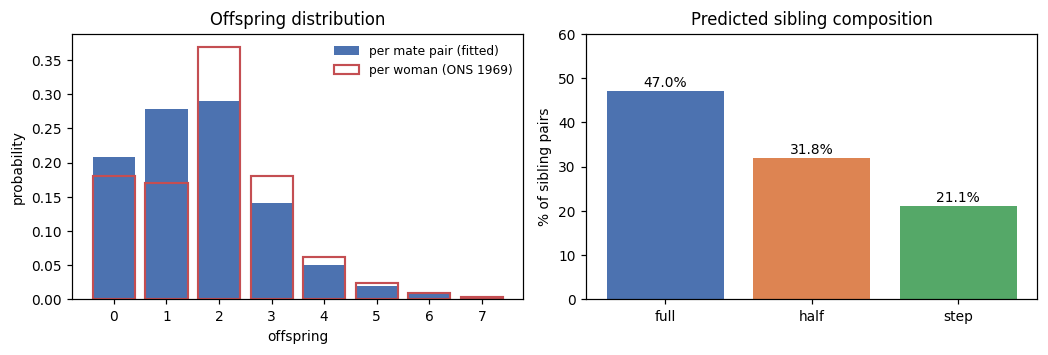

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.3))

ax1.bar(range(len(F_UK[:8])), F_UK[:8], color="#4C72B0", label="per mate pair (fitted)")
ax1.bar(np.arange(len(f_woman[:8])) + 0.0, f_woman[:8], color="none",
        edgecolor="#C44E52", lw=1.4, label="per woman (ONS 1969)")
ax1.set_xlabel("offspring")
ax1.set_ylabel("probability")
ax1.set_title("Offspring distribution")
ax1.legend(frameon=False, fontsize=8)

comp = [100 * (nf / tot).mean(), 100 * (nh / tot).mean(), 100 * (ns / tot).mean()]
ax2.bar(["full", "half", "step"], comp, color=["#4C72B0", "#DD8452", "#55A868"])
for i, v in enumerate(comp):
    ax2.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax2.set_ylabel("% of sibling pairs")
ax2.set_title("Predicted sibling composition")
ax2.set_ylim(0, 60)
plt.tight_layout()
plt.show()

---
## 6. Where this does not hold

Three things, in descending order of how much they should change your confidence.

### 6a. There is no UK sibling-composition target, so the composition is unvalidated

This was checked rather than assumed. The **2021 Census does not distinguish full siblings from
half siblings**; the only sibling-adjacent statement in the families release is that children
sharing a second parental address are "*assumed to be siblings*". Step-family statistics (8.8% of
dependent children in 2021) count **households containing a step-parent *or* step-sibling
relationship** — a different object from a sibling-pair count, and not decomposable into one.

So the composition in section 5 is what the fitted model *implies*. Fitting it directly was not
possible.

### 6b. Against Nordic register data, step-siblings overshoot by roughly 8x — and that is expected

Finland publishes what the UK does not, from full population registers. It is not the UK, so this
is a plausibility check rather than a target.

In [8]:
print(f"{'child-level prevalence':<28}{'simulated':>12}{'Finland, 2000 cohort by 16':>30}")
print(f"   {'has >= 1 full-sib':<25}{col('prev_full_sibs').mean():>12.3f}{'--':>30}")
print(f"   {'has >= 1 half-sib':<25}{col('prev_half_sibs').mean():>12.3f}{'~0.25  (any half-sib)':>30}")
print(f"   {'has >= 1 step-sib':<25}{col('prev_step_sibs').mean():>12.3f}{'~0.04  (COHABITING step-sib)':>30}")

child-level prevalence         simulated    Finland, 2000 cohort by 16
   has >= 1 full-sib               0.833                            --
   has >= 1 half-sib               0.405         ~0.25  (any half-sib)
   has >= 1 step-sib               0.311  ~0.04  (COHABITING step-sib)


The step-sibling gap is the **co-residence** problem from section 1, and it is
not a fitting failure. Finland's ~4% counts step-siblings *living in the same household*. The
simulator counts every `N_mu = 3` topology in the pedigree, including a parent's long-ago
ex-partner's children by a third person — people who in life would be strangers. The mate graph
also has no way to end a partnership, so every mating stays an edge forever.

**Practical consequence: do not read the simulator's step-sibling count as a social step-sibling
count.** It is an upper bound, and a loose one.

### 6c. Half-siblings overshoot by ~1.5x, and this one is structural

Simulated 0.41 of children have a half-sibling; Finland reports a bit over 0.25. The cause is
worth stating because it is a genuine limit on what the model can express.

In [9]:
pop = simulate(Q_UK, F_UK, 0, N=6000)
vals, pairs = partners_with_children(pop)
par = np.asarray(pop.relations["parents"])
kids_of = defaultdict(int)
for a, b in par:
    if a >= 0:
        kids_of[a] += 1
    if b >= 0:
        kids_of[b] += 1

mpf_par = [p for p in kids_of if vals[p] >= 2]
mono_par = [p for p in kids_of if vals[p] == 1]
km = np.mean([kids_of[p] for p in mpf_par])
ko = np.mean([kids_of[p] for p in mono_par])
mpf = (vals[vals >= 1] >= 2).mean()

print(f"MPF among parents               : {mpf:.4f}")
print(f"mean children, MPF parents      : {km:.3f}")
print(f"mean children, monogamous       : {ko:.3f}      -> {km/ko:.2f}x")
print()
p_child = mpf * km / (mpf * km + (1 - mpf) * ko)
print(f"P(a random PARENT is MPF)       : {mpf:.4f}")
print(f"P(a random CHILD has an MPF parent): {p_child:.4f}   <- size-biased, much larger")
print(f"\nso 15% MPF among parents produces ~{100*col('prev_half_sibs').mean():.0f}% of CHILDREN with a half-sibling.")

MPF among parents               : 0.1543
mean children, MPF parents      : 4.267
mean children, monogamous       : 2.099      -> 2.03x

P(a random PARENT is MPF)       : 0.1543
P(a random CHILD has an MPF parent): 0.2706   <- size-biased, much larger

so 15% MPF among parents produces ~41% of CHILDREN with a half-sibling.


Two separate things are going on, and only the first is a modelling artifact.

**The size-biasing is real and not a bug.** A parent with more children is over-represented when
you sample a child, so 15% MPF *among parents* necessarily implies a much larger fraction of
*children* having a half-sibling. Anyone comparing an MPF statistic to a child-level sibling
statistic has to account for this; they are not the same number.

**The 2x is forced by the model.** The simulator draws each mate pair's offspring count
independently from `offspring_f`, so an individual with `k` mate pairs has, mechanically, `k` times
the expected offspring. Real multi-partner parents do have more children, but plausibly ~1.5x
rather than exactly 2x. **`mate_q` and `offspring_f` cannot express a different coupling** — there
is no parameter for "how much more fertile are multi-partner individuals". That is the main reason
the half-sibling prevalence lands high, and it is a limitation of the model rather than of the fit.

Fixing it would need offspring counts conditioned on mate count, which the current parameterization
has no room for. Worth knowing before trusting a child-level half-sibling number.

---
## Summary

| | |
|---|---|
| **Recommended** | `mate_q = [1.0, 0.1630, 0.0323, 0.0095]`, `offspring_f` as derived above |
| **Fitted to** | UK multi-partner fertility (BCS70 at 42), calibrated against *measured* MPF |
| **Shape from** | ONS completed-family-size distribution, women born 1969 |
| **Matches** | realized MPF to within ~2% of target; mean family size within 5% of UK cohort CFS |
| **Predicts (unvalidated)** | ~47% full / ~32% half / ~21% step among sibling pairs |
| **Known to overshoot** | step-siblings ~8x vs Nordic co-resident figures (definitional); half-siblings ~1.5x (structural) |

**Use it for** generating pedigrees whose *multi-partner fertility* is UK-realistic, which is what
drives half-sibling structure.

**Do not use it for** claims about how many people have a step-sibling in the social sense, or for
child-level half-sibling prevalence, without the corrections in section 6.